# Lecture 5 (packaging): exercise solutions

Worked solutions to the exercises in `python-packaging.ipynb`. The code is in `solution_files/`:
`arithmetic.py` (Exercise 1), the `mycoolpackage/` package (Exercise 2), and `primes.py`, `mean.py`,
`plots.py`, `card.py` and `complex_sqrt.py` (Exercises 4 to 8). Every output below was produced by running
them in the module's `mpm2026` environment.

## Exercise 1: a simple argument-parsing script

```python
"""Exercise 1: basic arithmetic from the command line, with argparse.

    python arithmetic.py -o add -n1 10 -n2 5
"""
import argparse
import sys


def main():
    # Create the parser
    parser = argparse.ArgumentParser(
        description="Perform basic arithmetic operations.")

    # Add arguments. `choices` makes argparse reject any other operation:
    # it prints an error message and exits with status 2.
    parser.add_argument('-o', '--operation', required=True,
                        choices=['add', 'subtract', 'multiply', 'divide'],
                        help='The operation to perform.')
    parser.add_argument('-n1', '--num1', type=float, required=True,
                        help='The first number.')
    parser.add_argument('-n2', '--num2', type=float, required=True,
                        help='The second number.')

    # Parse the arguments
    args = parser.parse_args()

    # Perform the operation
    if args.operation == 'add':
        result = args.num1 + args.num2
        symbol = '+'
    elif args.operation == 'subtract':
        result = args.num1 - args.num2
        symbol = '-'
    elif args.operation == 'multiply':
        result = args.num1 * args.num2
        symbol = '*'
    else:  # divide
        if args.num2 == 0:
            # Print the message to stderr and exit with status 1.
            sys.exit("Error: Division by zero is not allowed.")
        result = args.num1 / args.num2
        symbol = '/'
    print(f"The result of {args.num1} {symbol} {args.num2} is: {result}")


if __name__ == "__main__":
    main()
```

Some runs (the last line of each is the shell's exit status, `echo $?`):

```text
$ python arithmetic.py -o add -n1 10 -n2 5
The result of 10.0 + 5.0 is: 15.0
[exit status 0]
$ python arithmetic.py -o multiply -n1 10 -n2 5
The result of 10.0 * 5.0 is: 50.0
[exit status 0]
$ python arithmetic.py -o subtract -n1 -3 -n2 -5.5
The result of -3.0 - -5.5 is: 2.5
[exit status 0]
$ python arithmetic.py -o divide -n1 1 -n2 0
Error: Division by zero is not allowed.
[exit status 1]
$ python arithmetic.py -o power -n1 1 -n2 2
usage: arithmetic.py [-h] -o {add,subtract,multiply,divide} -n1 NUM1 -n2 NUM2
arithmetic.py: error: argument -o/--operation: invalid choice: 'power' (choose from 'add', 'subtract', 'multiply', 'divide')
[exit status 2]
$ python arithmetic.py -o add -n1 1
usage: arithmetic.py [-h] -o {add,subtract,multiply,divide} -n1 NUM1 -n2 NUM2
arithmetic.py: error: the following arguments are required: -n2/--num2
[exit status 2]
```

- `choices` does the checking of the operation for us: `argparse` prints the usage and an error message, and
  exits with status 2. Missing arguments are handled the same way, because of `required=True`.
- Division by zero is checked by hand. `sys.exit("...")` prints the message to the standard error and exits
  with status 1, so a shell script (or a CI job) that runs this one can tell that something went wrong. (The
  version in the 2025 notes printed the message but exited with status 0, i.e. "success".)
- Negative numbers work as values (`-n1 -3`): `argparse` only treats `-3` as an option if the parser has
  options that look like negative numbers.
- `argparse` writes the help for free (`python arithmetic.py -h`):

```text
usage: arithmetic.py [-h] -o {add,subtract,multiply,divide} -n1 NUM1 -n2 NUM2

Perform basic arithmetic operations.

options:
  -h, --help            show this help message and exit
  -o, --operation {add,subtract,multiply,divide}
                        The operation to perform.
  -n1, --num1 NUM1      The first number.
  -n2, --num2 NUM2      The second number.
```

## Exercise 2: building a numerical package from scratch

`solution_files/mycoolpackage/` follows the suggested layout:

```text
mycoolpackage/
├── pyproject.toml
├── README.md
├── LICENSE
├── .gitignore
├── mycoolpackage/
│   ├── __init__.py
│   ├── linear_algebra/
│   │   ├── __init__.py
│   │   ├── _checks.py
│   │   ├── matrix_operations.py
│   │   └── array_operations.py
│   └── statistics/
│       ├── __init__.py
│       └── statistics.py
└── tests/
    └── test_mycoolpackage.py
```

Points worth noticing:

- **`pyproject.toml`** declares NumPy in `dependencies`, the `dev` tools as optional dependencies, and the
  license in the current form (`license = "MIT"`, `license-files = ["LICENSE"]`), so `setuptools>=77.0.3`.
- **`__init__.py` files** import the public functions, so users write `import mycoolpackage as mcp` and
  `mcp.mean(x)` rather than `from mycoolpackage.statistics.statistics import mean`. Each module lists its
  public names in `__all__`; the shape check shared by both `linear_algebra` modules is in `_checks.py`, whose
  leading underscore marks it as internal (DRY).
- **Docstrings** follow the NumPy style, each with an `Examples` section that `doctest` can run (Lecture 4).
- **Errors are explicit:** arrays of different shapes raise `ValueError` (rather than broadcasting silently),
  and `divide_arrays` raises `ZeroDivisionError` where NumPy itself would only warn and return `inf` or `nan`.
  Each of these promises has a test, with `pytest.raises`.
- **Floats** are compared with a tolerance (`pytest.approx`, `np.testing.assert_allclose`), as in Lecture 4.

From the folder containing `pyproject.toml`, in `mpm2026`:

```bash
pip install -e ".[dev]"
pytest --doctest-modules
flake8 .
```

`pytest --doctest-modules` runs the tests and the docstring examples: **27 passed**. `flake8 .` prints
nothing.

Building the package (with `build` and `twine` installed: `pip install build twine`):

```text
$ python -m build
...
Successfully built mycoolpackage-0.1.0.tar.gz and mycoolpackage-0.1.0-py3-none-any.whl
$ twine check dist/*
Checking dist/mycoolpackage-0.1.0-py3-none-any.whl: PASSED
Checking dist/mycoolpackage-0.1.0.tar.gz: PASSED
```

The wheel holds the package and its metadata (and not the tests):

```text
mycoolpackage/__init__.py
mycoolpackage/linear_algebra/__init__.py
mycoolpackage/linear_algebra/_checks.py
mycoolpackage/linear_algebra/array_operations.py
mycoolpackage/linear_algebra/matrix_operations.py
mycoolpackage/statistics/__init__.py
mycoolpackage/statistics/statistics.py
mycoolpackage-0.1.0.dist-info/licenses/LICENSE
mycoolpackage-0.1.0.dist-info/METADATA
mycoolpackage-0.1.0.dist-info/WHEEL
mycoolpackage-0.1.0.dist-info/top_level.txt
mycoolpackage-0.1.0.dist-info/RECORD
```

Installed from the wheel into a new, empty virtual environment, the package brings NumPy with it, because
`pyproject.toml` declares it:

```text
2.5 (numpy 2.5.3 installed as a dependency)
```

The second half of the lecture (`continuous-integration.ipynb`) ends by giving this package a GitHub repository
and two workflows; they are in `mycoolpackage/.github/workflows/` (see `ci_solutions.ipynb`).

## Exercise 3: running Python code

In a notebook and in the plain interpreter (`python`) the first snippet prints the same:

In [1]:
def square_and_cube(n):
    return sorted([i**2 for i in range(n)] + [i**3 for i in range(n)])


print(square_and_cube(3))
print(square_and_cube(10))

[0, 0, 1, 1, 4, 8]
[0, 0, 1, 1, 4, 8, 9, 16, 25, 27, 36, 49, 64, 64, 81, 125, 216, 343, 512, 729]


With 4th powers too, and in reverse order (`help(sorted)` in the plain interpreter shows the `reverse`
keyword; `sorted?` works only in IPython and Jupyter):

In [2]:
def square_cube_and_fourth(n):
    return sorted([i**2 for i in range(n)] + [i**3 for i in range(n)] + [i**4 for i in range(n)],
                  reverse=True)


print(square_cube_and_fourth(3))

[16, 8, 4, 1, 1, 1, 0, 0, 0]


The plotting snippet shows the figure straight away in a notebook. In the plain interpreter, `plt.plot`
only returns a list of `Line2D` objects: nothing appears until you call `plt.show()` (which opens a window, if
your system can open one).

## Exercise 4: find the primes

```python
"""Exercise 4: the first 20 prime numbers, or the primes below n.

    python primes.py        # the first 20 primes
    python primes.py 50     # the primes smaller than 50
"""
import math
import sys


def is_prime(n, smaller_primes):
    """Return True if n is prime, given all the primes smaller than n."""
    for p in smaller_primes:
        if p > math.isqrt(n):  # no factor up to sqrt(n): n is prime
            return True
        if n % p == 0:  # p divides n exactly
            return False
    return n > 1


def first_primes(count):
    """Return a list of the first `count` prime numbers."""
    primes = []
    n = 2
    while len(primes) < count:
        if is_prime(n, primes):
            primes.append(n)
        n += 1
    return primes


def primes_below(limit):
    """Return a list of the prime numbers smaller than `limit`."""
    primes = []
    for n in range(2, limit):
        if is_prime(n, primes):
            primes.append(n)
    return primes


if __name__ == "__main__":
    if len(sys.argv) > 1:
        print(primes_below(int(sys.argv[1])))
    else:
        print(first_primes(20))
```

```text
$ python primes.py
[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71]
[exit status 0]
$ python primes.py 50
[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47]
[exit status 0]
```

Only the primes found so far are tried as divisors, and only up to $\sqrt{n}$ (`math.isqrt` is the integer
square root). The tips in the 2025 notes had the modulus test the wrong way round: if `a` divides `b`, it is
`b % a` that is zero.

## Exercise 5: find the mean

```python
"""Exercise 5: the mean of a sequence of numbers.

    python mean.py 1 5 7 13 8
    python mean.py -x 2A 10     # hexadecimal; -b for binary, -o for octal
"""
import argparse
import sys


def main():
    parser = argparse.ArgumentParser(
        description="Print the mean of a sequence of numbers.")
    parser.add_argument('numbers', nargs='*',
                        help='The numbers (decimal unless -b, -o or -x).')
    base = parser.add_mutually_exclusive_group()
    base.add_argument('-b', dest='base', action='store_const', const=2,
                      help='The numbers are binary (base 2).')
    base.add_argument('-o', dest='base', action='store_const', const=8,
                      help='The numbers are octal (base 8).')
    base.add_argument('-x', dest='base', action='store_const', const=16,
                      help='The numbers are hexadecimal (base 16).')
    args = parser.parse_args()

    if not args.numbers:
        sys.exit("Error: give at least one number.")
    try:
        if args.base:
            values = [int(n, args.base) for n in args.numbers]
        else:
            values = [float(n) for n in args.numbers]
    except ValueError as err:
        sys.exit(f"Error: {err}")
    print(sum(values) / len(values))


if __name__ == "__main__":
    main()
```

```text
$ python mean.py 1
1.0
[exit status 0]
$ python mean.py 1 5 7 13 8
6.8
[exit status 0]
$ python mean.py 2.5 4 -3.2 9.3
3.1500000000000004
[exit status 0]
$ python mean.py
Error: give at least one number.
[exit status 1]
$ python mean.py -b 101 11
4.0
[exit status 0]
$ python mean.py -o 31 7
16.0
[exit status 0]
$ python mean.py -x 2A 10
29.0
[exit status 0]
$ python mean.py 2.5, 4
Error: could not convert string to float: '2.5,'
[exit status 1]
```

The last run shows why the 2025 notes' third test sequence, written with commas (`2.5, 4 ,-3.2, 9.3`), had to
change: command-line arguments are separated by spaces, so `2.5,` is passed as it is, and is not a number.
`-3.2` is fine as a value: `argparse` only treats it as an option if the parser has options that look like
negative numbers. The three base options are mutually exclusive. The mean of `2.5 4 -3.2 9.3` prints as
`3.1500000000000004`, not `3.15`: -3.2 and 9.3 cannot be stored exactly in binary floating point, so the
sum comes out as `12.600000000000001` (Lecture 7 explains why). Format the result, e.g. `f"{result:.2f}"`, if
you want `3.15`.

## Exercise 6: plots in scripts

```python
"""Exercise 6: plot sin, cos and tan over [0, 2 pi], on screen and to files.

    python plots.py
"""
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 2*np.pi, 1001)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label=r'$\sin(x)$')
ax.plot(x, np.cos(x), label=r'$\cos(x)$')
ax.plot(x, np.tan(x), label=r'$\tan(x)$')
ax.set_ylim(-3, 3)  # tan(x) goes to +/- infinity at pi/2 and 3 pi/2
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.legend()
fig.savefig('trig.png')
fig.savefig('trig.pdf')
plt.show()  # shows the plot in a window, if your system can open one
```

`python plots.py` writes `trig.pdf` and `trig.png`. Without `ax.set_ylim`, $\tan(x)$, which goes to
$\pm\infty$ at $\pi/2$ and $3\pi/2$, would set the scale and flatten the other two curves. Here is the same
figure in the notebook:

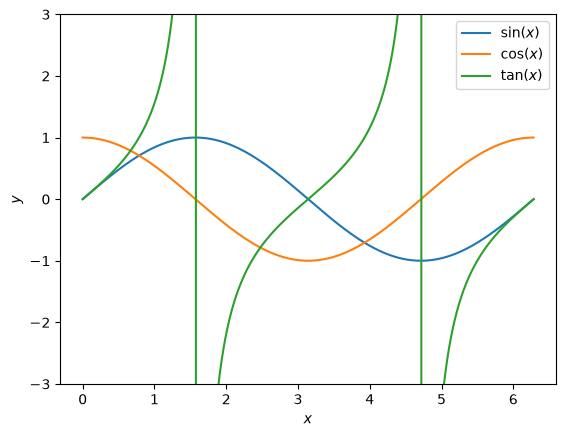

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 2*np.pi, 1001)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label=r'$\sin(x)$')
ax.plot(x, np.cos(x), label=r'$\cos(x)$')
ax.plot(x, np.tan(x), label=r'$\tan(x)$')
ax.set_ylim(-3, 3)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.legend();

## Exercise 7: fix the script

`flake8` on the original script reports 48 messages (codes E111, E201, E225, E228, E231, E251, E271, E272, E302, E303, E305, E501, E703, W291, W293): missing
whitespace around operators and after commas, a semicolon, trailing whitespace, a 3-space indent, too many and
too few blank lines, and so on. The fixed script, `solution_files/card.py`, passes `flake8` and prints the
same:

```python
"""Exercise 7: the script, fixed so that flake8 reports nothing."""

value = {1: 'Ace', 11: 'Jack', 12: 'Queen', 13: 'King'}
for number in range(2, 11):
    value[number] = number
suit = {0: 'Spades', 1: 'Hearts', 2: 'Diamonds', 3: 'Clubs'}


def the_name_of_your_card(v, s=0, *args, **kwargs):
    """Name of card as a string."""
    if v < 1 or v > 13 or s not in (0, 1, 2, 3):
        raise ValueError
    return ("I have read your mind and predict your card is the "
            f"{value[v]} of {suit[s]}.")


print(the_name_of_your_card(2, s=3))
```

```text
I have read your mind and predict your card is the 2 of Clubs.
```

Beyond what `flake8` asks for: the loop variable is named (`_` conventionally means "not used", but here it
is used), and the `%` formatting is now an f-string.

## Exercise 8: complex square root

```python
"""Exercise 8: the complex square roots of a real number."""
import math


def complex_sqrt(x):
    """
    Return the square roots of a real number, as complex numbers.

    Parameters
    ----------
    x : float
        A real number (positive, negative or zero).

    Returns
    -------
    tuple of complex
        The two square roots, ``(r, -r)``. Zero has only one square root,
        so for ``x == 0`` the tuple has a single element.

    Examples
    --------
    >>> complex_sqrt(4)
    ((2+0j), (-2-0j))
    >>> complex_sqrt(-9)
    (3j, (-0-3j))
    >>> complex_sqrt(0)
    (0j,)
    """
    if x == 0:
        return (0j,)
    if x > 0:
        r = complex(math.sqrt(x), 0)
    else:
        r = complex(0, math.sqrt(-x))
    return (r, -r)
```

`python -m doctest -v complex_sqrt.py` runs the examples in the docstring:

```text
3 passed.
Test passed.
```

Every non-zero real number has exactly two complex square roots, $\pm r$: real for $x > 0$, purely imaginary
for $x < 0$. Zero is the exception: it has just one, $0$. (The `-0` in `(-0-3j)` is IEEE floating-point's
negative zero, which compares equal to `0`: see Lecture 7.)

In [4]:
from complex_sqrt import complex_sqrt

for x in [4, -9, 2, 0]:
    roots = complex_sqrt(x)
    print(x, roots, [r**2 for r in roots])

4 ((2+0j), (-2-0j)) [(4+0j), (4+0j)]
-9 (3j, (-0-3j)) [(-9+0j), (-9+0j)]
2 ((1.4142135623730951+0j), (-1.4142135623730951-0j)) [(2.0000000000000004+0j), (2.0000000000000004+0j)]
0 (0j,) [0j]
